# COSMOS — Satellite Health, Space Debris and Atmospheric Re-entry

**AI-Enabled Space Environment Digital Twin**

A rocket discards parts at every stage. Some fall straight back through the atmosphere;
some stay in outer space. Once the satellite reaches its orbit, its health has to be
monitored. This project joins those three problems into one system:

| | Feature | Question it answers |
|---|---|---|
| **1** | Satellite health monitoring | Is the newly launched satellite healthy? |
| **2** | Debris generation in space | What was left in orbit, and how long will it stay? |
| **3** | Re-entry to the atmosphere | Where will each discarded part land, and who is at risk? |

They are **one chain, not three tools**: the satellite's health decides *how* it breaks up,
which sets the fragment cloud that re-enters — so the same alarm gives a different landing
footprint depending on which subsystem failed.

> All the work lives in the `cosmos` package. Every cell below is one or two lines.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import cosmos
from cosmos import plots

print("cosmos", cosmos.__version__)

cosmos 1.0.0


---
# Feature 1 — Satellite Health Monitoring

Telemetry from 8 subsystems (16 channels). We inject a **propellant leak** part-way through
and ask the monitor to find it without being told when.

In [2]:
ts = cosmos.health.simulate_telemetry(hours=24, faults={"Propulsion System": "leak"})
cosmos.Table(ts.summary())

samples            2880
duration_h         24.0
channels           16
subsystems         8
faults             Propulsion System (leak)
fault_onset_index  1584

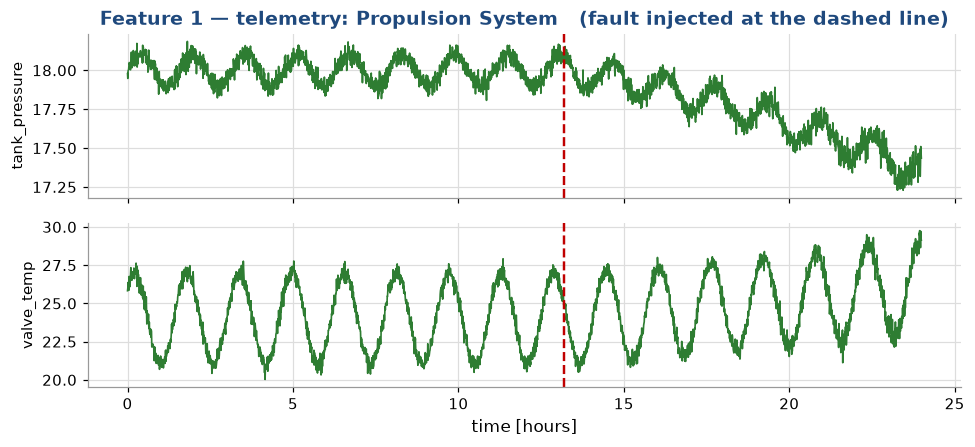

In [3]:
plots.plot_telemetry(ts, "Propulsion System");

### Detecting it

The monitor learns each channel's normal behaviour from an early healthy window, then scores
every later sample. It is never told the fault time.

In [4]:
res = cosmos.health.HealthMonitor().fit(ts).score(ts)
cosmos.Table(res.summary())

method               ewma
train_samples        1152
final_anomaly_score  0.976
worst_subsystem      Propulsion System
worst_degradation    0.976
band                 CRITICAL
first_alarm_index    2220

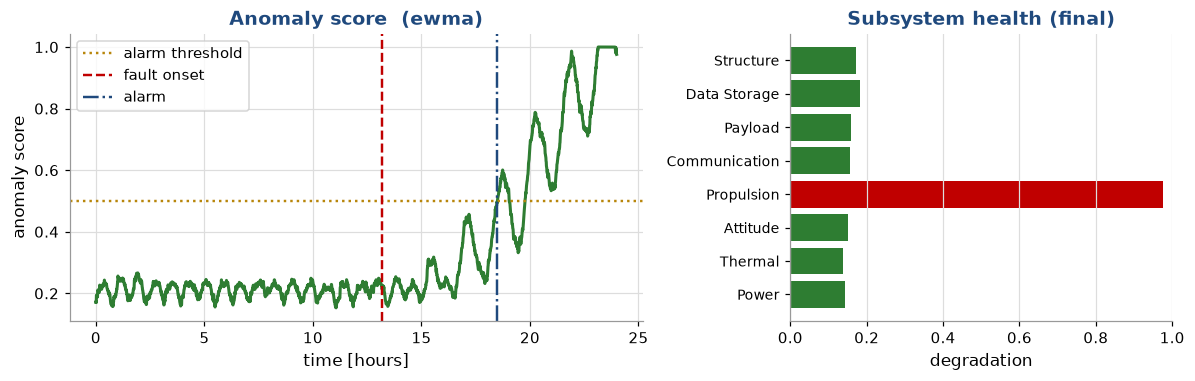

In [5]:
plots.plot_health(ts, res);

In [6]:
cosmos.Table(cosmos.health.detection_delay(ts, res))

fault          True
detected       True
onset_index    1584
alarm_index    2220
delay_samples  636
delay_minutes  318.0
before_onset   False

### The coupling — this is the novel part

A health monitor normally stops at the alarm. Here the **type** of failure selects the
break-up physics that Feature 3 propagates. Same anomaly score, different subsystem →
different break-up altitude, different fragmentation probability, different footprint width.

In [7]:
scen = cosmos.health.scenario_table()
scen

,scenario,anomaly_score,driver,breakup_type,breakup_altitude_km,p_fragmentation,bc_sigma_log10,state_sigma_m,band
0,all nominal,0.05,Power System,explosion,79.3,0.009,0.167,841.0,NOMINAL
1,thermal critical,0.85,Thermal Control,aerodynamic,69.8,0.129,0.199,1561.0,CRITICAL
2,power critical,0.85,Power System,explosion,76.6,0.103,0.191,1561.0,CRITICAL
3,attitude critical,0.85,Attitude Control,aerodynamic,80.7,0.099,0.190,3144.0,CRITICAL
4,comms + storage lost,0.85,Communication,aerodynamic,78.3,0.056,0.176,9101.0,CRITICAL
5,structure compromised,0.85,Structure,aerodynamic,63.2,0.150,0.204,1561.0,CRITICAL
6,propulsion critical,0.85,Propulsion System,explosion,83.0,0.400,0.243,1561.0,CRITICAL
7,propulsion + attitude,0.90,Attitude Control,aerodynamic,75.0,0.574,0.243,3117.0,CRITICAL


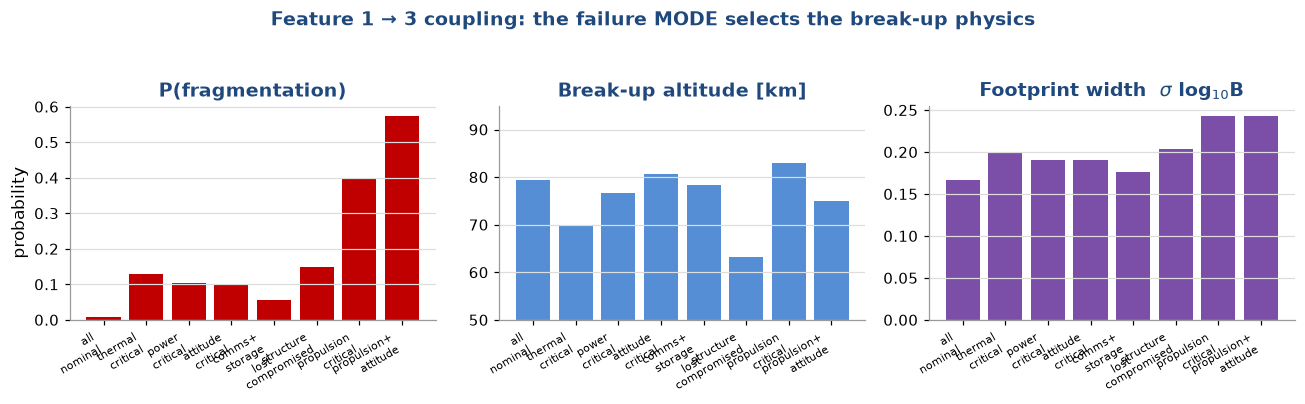

In [8]:
plots.plot_coupling(scen);

Read the middle and right panels together: **"comms + storage lost"** gives the largest
tracking uncertainty but among the *lowest* fragmentation probability. Losing telemetry makes
an object hard to **track**, not likely to break up. A model that confused uncertainty with
danger would raise the alarm on exactly the wrong failure.

---
# Feature 2 — Debris Generation in Space

## 2a. The real catalogue

CelesTrak SATCAT — the public US Space Force catalogue, no credentials needed. This is real
data, stored locally in `data/feature2_debris/celestrak/`.

In [9]:
cat = cosmos.debris.load_satcat()
cosmos.debris.catalogue_overview(cat)

,objects,decayed,still_in_orbit,percent_decayed
OBJECT_TYPE,,,,
DEB,35834,23335,12499,65.1
PAY,27414,7566,19848,27.6
R/B,6881,4460,2421,64.8
UNK,159,109,50,68.6


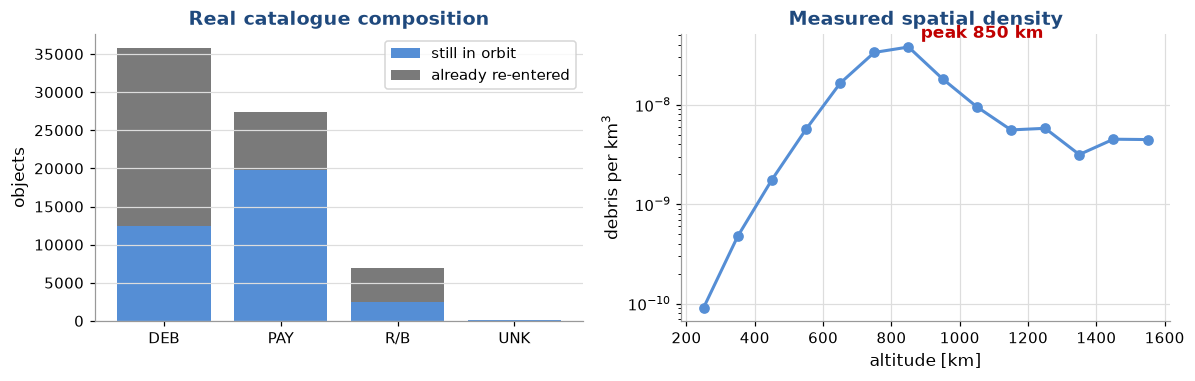

In [10]:
density = cosmos.debris.spatial_density(cat)
plots.plot_catalogue(cosmos.debris.catalogue_overview(cat), density);

### The four break-up clouds — and the one real label

For debris from a break-up whose **date and altitude are known**, `DECAY_DATE` minus the
break-up date is a *directly measured* orbital lifetime. That is real ground truth.

Fragments still in orbit are **right-censored** — we only know their lifetime is *at least*
their current age. Throwing them away biases the answer badly, which we measure below.

In [11]:
clouds = cosmos.debris.all_breakup_clouds(cat)
cosmos.debris.cloud_overview(clouds)

,event,altitude_km,fragments,decayed,percent_decayed,median_lifetime_years,censored
0,Cosmos 1408,480.0,1805,1801,99.8,0.525667,4
1,Iridium 33,789.0,656,539,82.2,13.149897,117
2,Cosmos 2251,789.0,1716,1097,63.9,15.238877,619
3,Fengyun-1C,865.0,3534,1215,34.4,NaN,2319


## 2b. Detecting debris in images

A single frame **cannot** separate a distant fragment from a star: both are unresolved point
sources through the same PSF, and the fragment is usually the fainter one. Motion is the
discriminator — so we register two frames to sub-pixel accuracy and subtract.

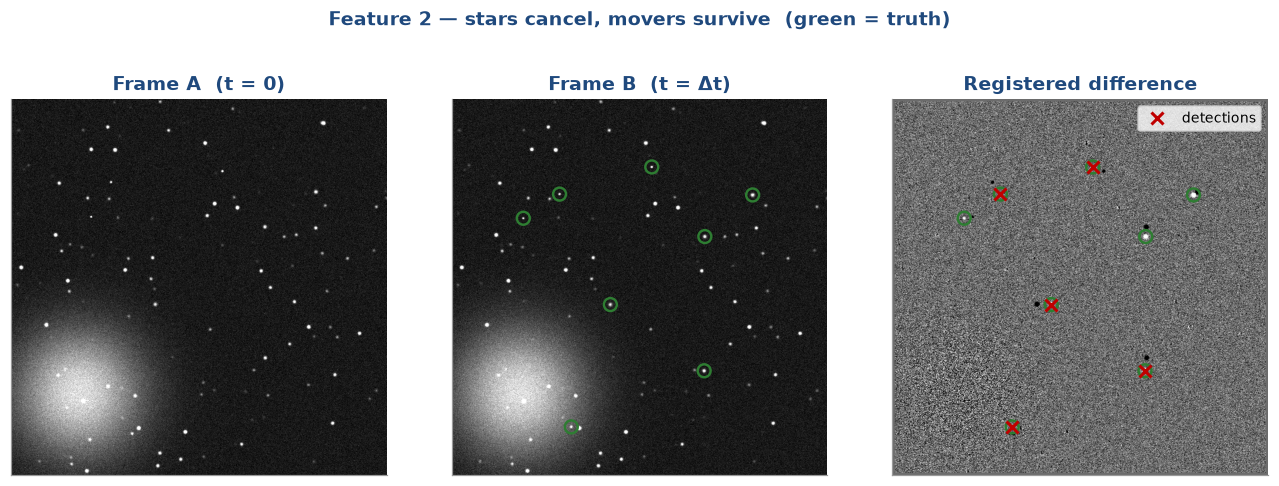

In [12]:
scene = cosmos.debris.make_scene(seed=1)
det = cosmos.debris.dog_detect(*[cosmos.debris.register_and_difference(scene.frame_a, scene.frame_b)[0]],
                               noise_map=cosmos.debris.photon_noise_map(scene.frame_a, scene.frame_b))
plots.plot_frames(scene, det);

In [13]:
print("single raw frame      :", cosmos.debris.single_frame_baseline(scene))
print("registered difference :", cosmos.debris.pair_detection(scene))

single raw frame      : {'n_truth': 8, 'n_pred': 76, 'tp': 8, 'fp': 68, 'fn': 0, 'precision': 0.1053, 'recall': 1.0, 'f1': 0.1905, 'mean_position_error_px': 0.137, 'tol_px': 3.0}
registered difference : {'n_truth': 8, 'n_pred': 5, 'tp': 5, 'fp': 0, 'fn': 3, 'precision': 1.0, 'recall': 0.625, 'f1': 0.7692, 'mean_position_error_px': 0.218, 'tol_px': 3.0, 'shift_error_px': 0.0466}


### Scored over many scenes

Note the **precision**: on raw frames the stars win.

In [14]:
ds = cosmos.debris.generate_dataset(n_scenes=16, seed=3)
scores = cosmos.debris.evaluate_dataset(ds)
cosmos.debris.aggregate(scores)

,detector,truth,predicted,true_positives,precision,recall,f1
0,single frame,135,1182,130,0.110,0.963,0.1974
1,registered difference,135,77,76,0.987,0.563,0.7170


## 2c. A learned detector (YOLO-style)

Following the approach of the reference pipeline
[jaikr-dev/space-debris-detection-pipeline](https://github.com/jaikr-dev/space-debris-detection-pipeline):
synthetic renders with domain randomisation, a YOLO-format dataset, a nano-scale single-stage
detector, mAP@50 and a confusion matrix, inference at confidence 0.60.

We export a real YOLO dataset (so Ultralytics could train on it directly), then train a small
anchor-free detector in PyTorch.

In [15]:
ds_big = cosmos.debris.generate_dataset(n_scenes=48, seed=11)
info = cosmos.debris.export_yolo_dataset(ds_big)
cosmos.Table({k: v for k, v in info.items() if k != "path"})

train_images  36
val_images    12
labels        381
image_size    640
classes       ['satellite', 'rocket_body', 'fragment', 'panel']
data_yaml     /data/ss/workspace/anupa/Satellite-Digital-Twin-for-Anomaly-Detection-and-Heath-Monitoring-System/Final_Project/data/feature2_debris/vision/yolo_dataset/data.yaml

In [16]:
model = cosmos.debris.TinyYOLO().fit(info["path"], epochs=50)   # ~1 minute on CPU
metrics = model.evaluate(info["path"], conf=0.60)
cm = metrics.pop("confusion_matrix")
cosmos.Table(metrics)

split      val
conf       0.6
tp         91
fp         12
fn         4
precision  0.8835
recall     0.9579
f1         0.9192
mean_iou   0.6109
map50      0.9465

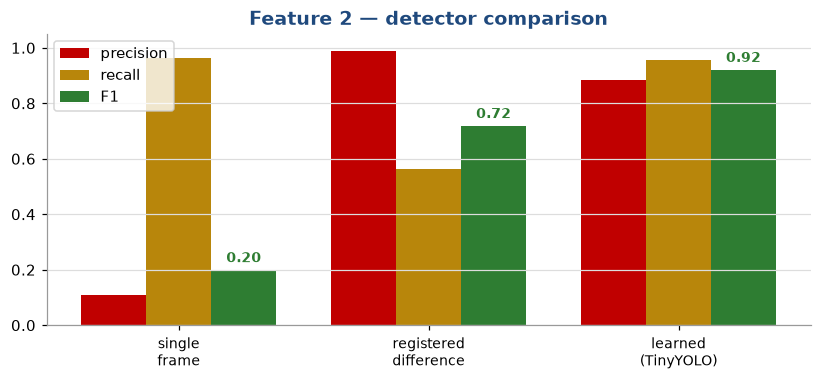

In [17]:
plots.plot_detector_scores(cosmos.debris.aggregate(scores), metrics);

**Honest reading.** Localisation is good (mAP@50 high, sub-pixel centres) but the *class*
confusion matrix below is poor: our four classes differ only subtly in size and brightness,
and the difference image discards much of that. Detection works; classification does not yet.

In [18]:
cm

,satellite,rocket_body,fragment,panel,(missed)
satellite,7,8,1,5,0
rocket_body,5,21,0,2,0
fragment,0,0,11,4,4
panel,8,2,6,11,0
(background),0,1,6,5,0


In [19]:
cosmos.debris.reference_benchmark()   # the reference pipeline's own published numbers

,model,mAP50-95,source
0,YOLOv8n,0.976,reference pipeline (Blender data)
1,YOLOv11n,0.976,reference pipeline (Blender data)
2,YOLOv12n,0.969,reference pipeline (Blender data)


## 2d. How long does it stay up?

The lifetime model is **physics, not a fit** — it integrates energy lost to drag using the
US-76 density. Its one free parameter is area-to-mass, which we calibrate against the real
measured decay times, *accounting for censoring*.

In [20]:
cal = cosmos.debris.calibrate_area_to_mass(clouds)
cosmos.Table({k: v for k, v in cal.items() if k not in ("grid", "losses")})

KeyboardInterrupt: 

Note **`bias_factor`**: that is how far the fitted area-to-mass moves if you ignore the
fragments still in orbit. Discarding censored data is not a small approximation.

In [ ]:
validation = cosmos.debris.validate_lifetimes(clouds, cal["area_to_mass_censored"])
validation

In [ ]:
plots.plot_lifetime(cosmos.debris.lifetime_profile(area_to_mass=cal["area_to_mass_censored"]),
                    validation);

### Collision risk while it is up there

In [ ]:
risk_shells = cosmos.debris.collision_risk(density)
cosmos.Table(cosmos.debris.total_leo_collision_rate(risk_shells))

---
# Feature 3 — Re-entry to the Atmosphere

## 3a. The physics: atmosphere and drag

$C_D$ is **not** a constant. It rises through the transonic regime and again as the flow goes
free-molecular — which is exactly where a re-entering fragment spends its first minute.

In [ ]:
plots.plot_atmosphere(cosmos.reentry.profile_frame(), cosmos.reentry.sweep_frame("cylinder"));

## 3b. One fragment, fully resolved

A 200 kg stainless-steel tank section entering at 120 km. Peak heating and peak deceleration
happen at **different altitudes** — that separation falls out of the integration.

In [ ]:
tank = cosmos.reentry.DebrisObject("tank section", mass=200, area=0.15, shape="cylinder",
                                   material="stainless_steel")
tr = cosmos.reentry.propagate(cosmos.reentry.entry_state(120e3, 7500.0, -1.5), tank)
cosmos.Table(tr.summary())

In [ ]:
plots.plot_trajectory(tr);

## 3c. Why one predicted point is meaningless

Same entry state, different ballistic coefficient $B = m/(C_D A)$.

In [ ]:
hz_demo = cosmos.health.assess_hazard(0.85, cosmos.health.SubsystemHealth.nominal())
sweep = cosmos.reentry.ballistic_sweep(hz_demo)
plots.plot_ballistic_sweep(sweep);

## 3d. Break-up model → Monte Carlo footprint

NASA Standard Breakup Model. The published size and area-to-mass laws are sampled
independently, so nothing in them conserves the parent's mass — we enforce the budget in both
directions, and check that closure lands at 1.0.

In [ ]:
cloud = cosmos.reentry.sample_cloud(parent_mass=1800.0, kind="explosion", rng=7)
cosmos.Table(cloud.summary())

In [ ]:
fp = cosmos.reentry.monte_carlo_footprint(hz_demo, cloud,
        cosmos.reentry.DispersionConfig(n_samples=1200, seed=0))
cosmos.Table(fp.summary())

## 3e. Conformal impact zones — the headline result

A Gaussian covariance ellipse assumes a shape the dispersion does not have: fragment
footprints are **skewed** downrange. So a nominal 99 % ellipse does not contain 99 % of
impacts. A conformal zone calibrates its threshold on held-out samples instead, which gives
finite-sample coverage under nothing stronger than exchangeability.

Coverage below is measured **out-of-sample**: the zone is built on half the impacts and tested
on the other half.

In [ ]:
zones = cosmos.reentry.zone_comparison(fp, n_splits=12, seed=0)
zones[["nominal", "gaussian_ellipse_coverage", "conformal_ellipse_coverage",
       "conformal_density_coverage", "gaussian_shortfall_pts", "density_area_saving_pct"]]

In [ ]:
plots.plot_zone_comparison(zones);

In [ ]:
zone = cosmos.reentry.conformal_zone(fp.downrange_crossrange_km(), alpha=0.05, method="density")
plots.plot_footprint(fp, zone);

## 3f. Who is underneath — expected casualties

In [ ]:
cosmos.Table(cosmos.reentry.assess_footprint(fp))

---
# All three together — the end-to-end chain

`run_pipeline` executes: **telemetry → health → hazard → break-up → re-entry → footprint →
risk** in one call.

In [ ]:
result = cosmos.run_pipeline(faults={"Propulsion System": "leak"},
                             azimuth_deg=320.0, n_samples=800)
result.summary()

### The central experiment

Hold the anomaly score **fixed** and change only *which* subsystem failed. Any difference in
the footprint then comes from the failure mode, not from severity.

In [ ]:
table, results = cosmos.compare_failure_modes(n_samples=600)
table[["scenario", "driver", "breakup_type", "breakup_alt_km", "P_fragmentation",
       "sigma_logB", "downrange_mean_km", "cep50_km", "risk_band"]]

In [ ]:
plots.plot_failure_mode_footprints(results);

---
# Verification

Every check has an answer that does **not** come from this code — a published table, a
closed-form solution, or a property the physics must satisfy.

In [ ]:
import subprocess
print(subprocess.run([sys.executable, "../tests/test_verify.py"],
                     capture_output=True, text=True).stdout[-2200:])

---
# Summary

| Feature | What works | Honest limitation |
|---|---|---|
| **1 Health** | 8-subsystem monitor detects an injected fault it was never told about; failure *mode* drives break-up physics | Telemetry is simulated — real benchmarks (ESA-ADB, NASA SMAP/MSL) not yet ingested |
| **2 Debris** | Real catalogue (70k objects); differencing lifts detection precision from ~0.11 to ~0.99; lifetime model validated against real decay dates | Imagery is synthetic; **class** discrimination is poor |
| **3 Re-entry** | Atmosphere matches published tables to <0.01 %; conformal zones beat the Gaussian ellipse on coverage *and* area | Landing **location** never validated against a real recovered fragment; population raster is coarse |

**The one thing still open:** the predicted landing *location* has not been checked against a
real recorded re-entry. That needs ESA DISCOS re-entry events, and it is the first task of the
project plan.